# Classification and cross-crash transfer

**Name:** Raaj Banga

Main result: how much predictive power is lost when a model trained on one crash is used on another, and which signals hold across crashes.

Lead with AUC, and report PR-AUC, Brier score, and accuracy alongside it. Fit all preprocessing inside pipelines on training data only, and pick thresholds on training data only.

## Part 1: Setup

### Block 1: Imports and paths

In [1]:
# python 3.14.10, pandas 2.3.3, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2, lightgbm 4.7.0, shap 0.54.1, statsmodels 0.15.0
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import shap
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

# Find the project folder whether this runs from notebooks/ or the project root
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
from config import CRASHES, PROCESSED, SEED
from helpers import (CRASH_COLORS, CRASH_LABELS, CRASH_SHORT, load_firms, save_figure, set_style, bootstrap_ci, delong_test,
                     FEATURES, make_model, model_columns, to_ranks)

set_style()
import warnings
warnings.filterwarnings("ignore", message=".*feature names.*")

### Block 2: Load the data

In [2]:
# One row per firm per crash, from 07_build_features.py
firms = load_firms()
print(firms.shape)
print(firms["crash"].value_counts().to_string())

(10513, 70)
crash
tariff_2025    3698
rates_2022     3599
covid_2020     3216


## Part 2: Within-crash models

### Block 3: Feature lists and pipeline builder

Inside each pipeline, fit on training rows only: ratios are capped at the training 1st and 99th percentiles (`Winsorizer`), missing values get the training median, and logistic regression also standardizes. Missing flags and sector enter as features. Class weights are balanced, so the threshold for accuracy is a fixed 0.5, chosen before seeing any test data.

Hyperparameters are fixed (decided 2026-11-08), not tuned: regularized, shallow settings that suit about 3,500 rows per crash.

In [3]:
LABELS = {"recovered_12m": "Recovered in 12 months", "beat_market": "Beat SPY"}
FULL, BASE = model_columns(firms)
FLAGS = [f for f in FULL["flags"] if f != "is_financial"]
ORDER = list(CRASHES)
FORWARD = {(a, b) for i, a in enumerate(ORDER) for b in ORDER[i + 1:]}
# make_model, to_ranks, and FEATURES live in helpers.py (Section 6), shared with notebooks 03 and 04


MODELS = {"baseline": BASE, "logit": FULL, "forest": FULL, "lgbm": FULL}
MODEL_NAMES = {"baseline": "Baseline (sector, size)", "logit": "Logistic regression",
               "forest": "Random forest", "lgbm": "LightGBM"}


def scores(y, p):
    return {"auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "accuracy": accuracy_score(y, p >= 0.5),
            "base_rate": y.mean(), "n": len(y)}


print(f"{len(FEATURES)} features, {len(FLAGS)} missing flags, sector, is_financial")

16 features, 16 missing flags, sector, is_financial


### Block 4: Baseline: sector and size only

The bar fundamentals have to beat.

In [4]:
# Within-crash cross-validation for every model, baseline included. Out-of-fold
# predictions are kept for DeLong tests and bootstrap intervals in Part 4.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {}  # (label, crash, model) -> out-of-fold scores
for label in LABELS:
    for crash in ORDER:
        d = firms[firms["crash"] == crash].reset_index(drop=True)
        y = d[label].values
        folds = list(cv.split(d, y, groups=d["cik"]))
        for kind, cols in MODELS.items():
            p = np.zeros(len(d))
            for train, test in folds:
                m = make_model(kind, cols).fit(d.iloc[train], y[train])
                p[test] = m.predict_proba(d.iloc[test])[:, 1]
            oof[(label, crash, kind)] = p

within = pd.DataFrame([{"label": label, "crash": crash, "model": kind,
                        **scores(firms.loc[firms["crash"] == crash, label].values, p)}
                       for (label, crash, kind), p in oof.items()])
print("Baseline, within-crash cross-validation:")
print(within[within["model"] == "baseline"].set_index(["label", "crash"])
      [["auc", "pr_auc", "brier", "accuracy", "base_rate"]].round(3).to_string())

Baseline, within-crash cross-validation:
                             auc  pr_auc  brier  accuracy  base_rate
label         crash                                                 
recovered_12m covid_2020   0.623   0.823  0.236     0.653      0.756
              rates_2022   0.670   0.613  0.227     0.636      0.428
              tariff_2025  0.651   0.801  0.233     0.605      0.695
beat_market   covid_2020   0.645   0.594  0.231     0.618      0.477
              rates_2022   0.667   0.500  0.226     0.645      0.320
              tariff_2025  0.649   0.509  0.233     0.603      0.388


### Block 5: Logistic regression, random forest, and LightGBM

Within-crash cross-validation, grouped by firm, using `random_state=SEED`.

In [5]:
table = within.pivot_table(index=["label", "model"], columns="crash", values="auc")[ORDER]
table = table.reindex([(l, m) for l in LABELS for m in MODELS]).rename(columns=CRASH_SHORT)
print("AUC, within-crash 5-fold cross-validation grouped by firm:")
print(table.round(3).to_string())
print("\nAll metrics:")
print(within.set_index(["label", "crash", "model"])[["auc", "pr_auc", "brier", "accuracy"]]
      .round(3).to_string())

AUC, within-crash 5-fold cross-validation grouped by firm:
crash                    2020   2022   2025
label         model                        
recovered_12m baseline  0.623  0.670  0.651
              logit     0.647  0.701  0.670
              forest    0.683  0.709  0.676
              lgbm      0.678  0.703  0.674
beat_market   baseline  0.645  0.667  0.649
              logit     0.684  0.719  0.670
              forest    0.708  0.730  0.679
              lgbm      0.714  0.731  0.678

All metrics:
                                      auc  pr_auc  brier  accuracy
label         crash       model                                   
recovered_12m covid_2020  baseline  0.623   0.823  0.236     0.653
                          logit     0.647   0.831  0.231     0.623
                          forest    0.683   0.860  0.202     0.718
                          lgbm      0.678   0.857  0.199     0.693
              rates_2022  baseline  0.670   0.613  0.227     0.636
                  

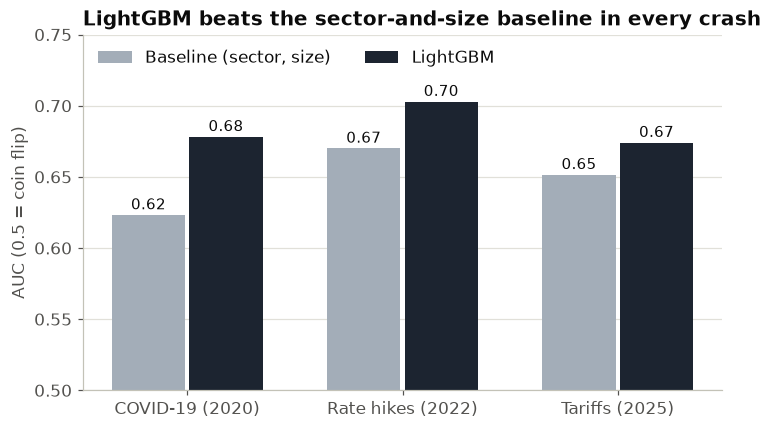

In [6]:
# Figure for the slides: baseline vs LightGBM, recovered within 12 months
auc = within[within["label"] == "recovered_12m"].pivot_table(index="crash", columns="model", values="auc").loc[ORDER]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(ORDER))
for k, (model, color) in enumerate([("baseline", "#a3adb8"), ("lgbm", "#1c2430")]):
    xs = x + (k - 0.5) * 0.36
    ax.bar(xs, auc[model], 0.34, color=color, label=MODEL_NAMES[model])
    for xi, v in zip(xs, auc[model]):
        ax.text(xi, v + 0.004, f"{v:.2f}", ha="center", fontsize=10)
ax.set_xticks(x, [CRASH_LABELS[c] for c in ORDER])
ax.set_ylim(0.5, 0.75)
ax.set_ylabel("AUC (0.5 = coin flip)")
ax.set_title("LightGBM beats the sector-and-size baseline in every crash")
ax.legend(loc="upper left", ncol=2)
save_figure(fig, "within_auc")
plt.show()

## Part 3: Cross-crash evaluation (main result)

### Block 6: Every train-on-one, test-on-another pair

Mark forward-in-time pairs, since backward pairs couldn't happen in real use.

In [7]:
# Train on all rows of one crash, test on each other crash
cross_pred = {}  # (label, train, test, model) -> scores on the test crash
for label in LABELS:
    for train in ORDER:
        d_train = firms[firms["crash"] == train]
        for kind, cols in MODELS.items():
            m = make_model(kind, cols).fit(d_train, d_train[label])
            for test in ORDER:
                if test != train:
                    d_test = firms[firms["crash"] == test]
                    cross_pred[(label, train, test, kind)] = m.predict_proba(d_test)[:, 1]

cross = pd.DataFrame([{"label": label, "train": tr, "test": te, "model": kind,
                       "direction": "forward" if (tr, te) in FORWARD else "backward",
                       **scores(firms.loc[firms["crash"] == te, label].values, p)}
                      for (label, tr, te, kind), p in cross_pred.items()])
print(cross[cross["model"].isin(["baseline", "lgbm"])]
      .assign(train=lambda d: d["train"].map(CRASH_SHORT), test=lambda d: d["test"].map(CRASH_SHORT))
      .set_index(["label", "model", "train", "test", "direction"])[["auc", "pr_auc", "brier", "accuracy"]]
      .round(3).to_string())

                                               auc  pr_auc  brier  accuracy
label         model    train test direction                                
recovered_12m baseline 2020  2022 forward    0.468   0.444  0.275     0.430
                             2025 forward    0.443   0.679  0.267     0.505
              lgbm     2020  2022 forward    0.457   0.403  0.333     0.432
                             2025 forward    0.517   0.709  0.248     0.590
              baseline 2022  2020 backward   0.463   0.721  0.283     0.484
                             2025 forward    0.618   0.774  0.247     0.558
              lgbm     2022  2020 backward   0.456   0.722  0.276     0.545
                             2025 forward    0.602   0.767  0.262     0.574
              baseline 2025  2020 backward   0.426   0.712  0.269     0.497
                             2022 backward   0.633   0.537  0.240     0.593
              lgbm     2025  2020 backward   0.456   0.710  0.257     0.575
            

### Block 7: Leave-one-crash-out

Train on two crashes, test on the third.

In [8]:
loco_pred = {}  # (label, test, model) -> scores
for label in LABELS:
    for test in ORDER:
        d_train = firms[firms["crash"] != test]
        d_test = firms[firms["crash"] == test]
        for kind, cols in MODELS.items():
            m = make_model(kind, cols).fit(d_train, d_train[label])
            loco_pred[(label, test, kind)] = m.predict_proba(d_test)[:, 1]

loco = pd.DataFrame([{"label": label, "test": te, "model": kind,
                      **scores(firms.loc[firms["crash"] == te, label].values, p)}
                     for (label, te, kind), p in loco_pred.items()])
print(loco.pivot_table(index=["label", "model"], columns="test", values="auc")[ORDER]
      .reindex([(l, m) for l in LABELS for m in MODELS]).rename(columns=CRASH_SHORT).round(3).to_string())

test                     2020   2022   2025
label         model                        
recovered_12m baseline  0.442  0.588  0.586
              logit     0.445  0.529  0.571
              forest    0.429  0.540  0.544
              lgbm      0.422  0.518  0.546
beat_market   baseline  0.467  0.580  0.532
              logit     0.469  0.512  0.509
              forest    0.442  0.492  0.480
              lgbm      0.452  0.486  0.478


### Block 8: AUC lost between crashes

For each test crash: its within-crash cross-validated AUC minus the AUC of a model trained on a different crash (or on the other two). Positive means accuracy is lost when the crash changes. Then the same for LightGBM with within-crash percentile features, the robustness check decided on 2026-11-08.


Recovered in 12 months: AUC lost vs within-crash, by model (rows) and test crash
test                  2020   2022   2025
model    trained on                     
baseline 2020 (fwd)    NaN  0.202  0.208
         2022 (bwd)  0.161    NaN    NaN
         2022 (fwd)    NaN    NaN  0.033
         2025 (bwd)  0.197  0.037    NaN
         other two   0.181  0.082  0.065
forest   2020 (fwd)    NaN  0.254  0.171
         2022 (bwd)  0.220    NaN    NaN
         2022 (fwd)    NaN    NaN  0.082
         2025 (bwd)  0.224  0.113    NaN
         other two   0.255  0.169  0.132
lgbm     2020 (fwd)    NaN  0.246  0.157
         2022 (bwd)  0.222    NaN    NaN
         2022 (fwd)    NaN    NaN  0.072
         2025 (bwd)  0.222  0.124    NaN
         other two   0.256  0.185  0.128
logit    2020 (fwd)    NaN  0.285  0.195
         2022 (bwd)  0.192    NaN    NaN
         2022 (fwd)    NaN    NaN  0.061
         2025 (bwd)  0.178  0.098    NaN
         other two   0.202  0.173  0.099

Beat SPY: AUC l

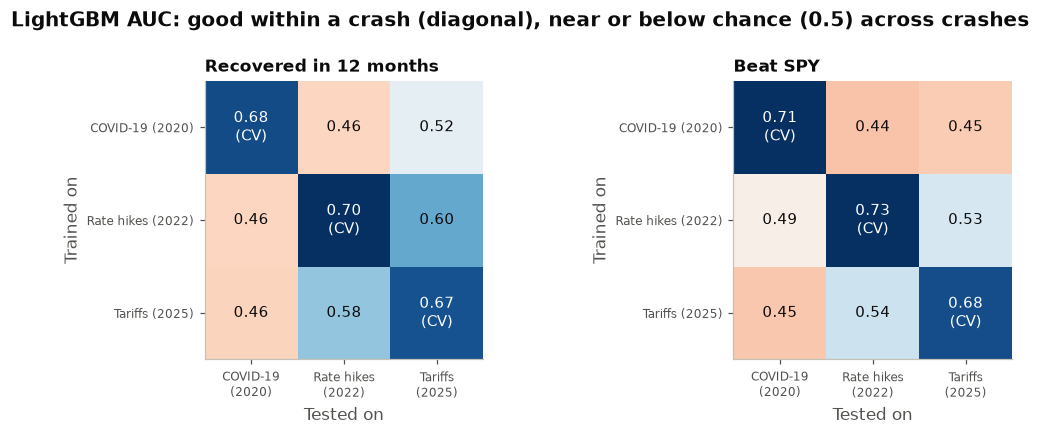


LightGBM cross-crash AUC, raw vs within-crash percentile features:
                          auc_ranks    auc  change
label         train test                          
recovered_12m 2020  2022      0.437  0.457  -0.019
                    2025      0.496  0.517  -0.022
              2022  2020      0.448  0.456  -0.008
                    2025      0.596  0.602  -0.006
              2025  2020      0.473  0.456   0.018
                    2022      0.601  0.579   0.022
beat_market   2020  2022      0.425  0.443  -0.017
                    2025      0.451  0.449   0.002
              2022  2020      0.457  0.488  -0.031
                    2025      0.537  0.534   0.002
              2025  2020      0.443  0.446  -0.003
                    2022      0.554  0.542   0.012
Mean change from using percentiles: -0.004

Cross-crash AUC for firms also in the training crash vs firms that weren't:
        label train test  auc_seen_firms  auc_new_firms  new_firms
recovered_12m  2020 2022       

In [9]:
def loss_table(within, cross, loco):
    w = within.set_index(["label", "crash", "model"])["auc"]
    rows = []
    for r in cross.itertuples():
        rows.append({"label": r.label, "model": r.model, "test": r.test,
                     "trained on": CRASH_SHORT[r.train] + (" (fwd)" if r.direction == "forward" else " (bwd)"),
                     "auc": r.auc, "loss": w[(r.label, r.test, r.model)] - r.auc})
    for r in loco.itertuples():
        rows.append({"label": r.label, "model": r.model, "test": r.test, "trained on": "other two",
                     "auc": r.auc, "loss": w[(r.label, r.test, r.model)] - r.auc})
    return pd.DataFrame(rows)

losses = loss_table(within, cross, loco)
for label in LABELS:
    print(f"\n{LABELS[label]}: AUC lost vs within-crash, by model (rows) and test crash")
    t = losses[losses["label"] == label].pivot_table(index=["model", "trained on"], columns="test", values="loss")
    print(t[ORDER].rename(columns=CRASH_SHORT).round(3).to_string())

summary = losses.groupby(["label", "model"])["loss"].agg(["mean", "min", "max"])
print("\nMean AUC lost across all cross-crash tests:")
print(summary.round(3).to_string())

# Heatmap for the slides: LightGBM AUC, train crash by test crash, diagonal = cross-validation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label in zip(axes, LABELS):
    grid = np.zeros((3, 3))
    for i, tr in enumerate(ORDER):
        for j, te in enumerate(ORDER):
            grid[i, j] = (within.query("label == @label and crash == @te and model == 'lgbm'")["auc"].item()
                          if tr == te else
                          cross.query("label == @label and train == @tr and test == @te and model == 'lgbm'")["auc"].item())
    ax.imshow(grid, cmap="RdBu", vmin=0.3, vmax=0.7)  # centered on 0.5: red = worse than chance
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{grid[i, j]:.2f}" + ("\n(CV)" if i == j else ""), ha="center", va="center",
                    color="white" if abs(grid[i, j] - 0.5) > 0.15 else "#0b0b0b", fontsize=10)
    ax.set_xticks(range(3), [CRASH_LABELS[c].replace(" (", "\n(") for c in ORDER], fontsize=8)
    ax.set_yticks(range(3), [CRASH_LABELS[c] for c in ORDER], fontsize=8)
    ax.set_xlabel("Tested on")
    ax.set_ylabel("Trained on")
    ax.set_title(LABELS[label], fontsize=11)
    ax.grid(False)
fig.suptitle("LightGBM AUC: good within a crash (diagonal), near or below chance (0.5) across crashes", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "transfer_auc")
plt.show()

# Robustness: LightGBM with within-crash percentile features
ranked = to_ranks(firms)
rank_rows = []
for label in LABELS:
    for train in ORDER:
        d_train = ranked[ranked["crash"] == train]
        m = make_model("lgbm", FULL).fit(d_train, d_train[label])
        for test in ORDER:
            if test != train:
                d_test = ranked[ranked["crash"] == test]
                rank_rows.append({"label": label, "train": train, "test": test,
                                  "auc_ranks": roc_auc_score(d_test[label], m.predict_proba(d_test)[:, 1])})
check = pd.DataFrame(rank_rows).merge(cross[cross["model"] == "lgbm"][["label", "train", "test", "auc"]],
                                      on=["label", "train", "test"])
check["change"] = check["auc_ranks"] - check["auc"]
print("\nLightGBM cross-crash AUC, raw vs within-crash percentile features:")
print(check.assign(train=lambda d: d["train"].map(CRASH_SHORT), test=lambda d: d["test"].map(CRASH_SHORT))
      .set_index(["label", "train", "test"]).round(3).to_string())
print(f"Mean change from using percentiles: {check['change'].mean():+.3f}")

# Firm overlap check: do test firms also seen in the training crash score better?
overlap = []
for (label, tr, te, kind), p in cross_pred.items():
    if kind != "lgbm":
        continue
    d = firms[firms["crash"] == te]
    seen = d["cik"].isin(firms.loc[firms["crash"] == tr, "cik"]).values
    overlap.append({"label": label, "train": CRASH_SHORT[tr], "test": CRASH_SHORT[te],
                    "auc_seen_firms": roc_auc_score(d[label][seen], p[seen]),
                    "auc_new_firms": roc_auc_score(d[label][~seen], p[~seen]), "new_firms": (~seen).sum()})
print("\nCross-crash AUC for firms also in the training crash vs firms that weren't:")
print(pd.DataFrame(overlap).round(3).to_string(index=False))

## Part 4: Significance

### Block 9: DeLong tests

`delong_test` from `helpers.py`: full model vs baseline on the same test rows.

In [10]:
# Each model vs the baseline, on the same test rows, in every setting
tests = []
def add_tests(setting, label, test_crash, preds):
    y = firms.loc[firms["crash"] == test_crash, label].values
    for kind in ["logit", "forest", "lgbm"]:
        r = delong_test(y, preds[kind], preds["baseline"])
        tests.append({"label": label, "setting": setting, "test": CRASH_SHORT[test_crash],
                      "model": kind, "auc_model": r["auc_a"], "auc_baseline": r["auc_b"],
                      "gain": r["diff"], "z": r["z"], "p": r["p"]})

for label in LABELS:
    for crash in ORDER:
        add_tests("within (CV)", label, crash, {k: oof[(label, crash, k)] for k in MODELS})
        add_tests("other two", label, crash, {k: loco_pred[(label, crash, k)] for k in MODELS})
        for tr in ORDER:
            if tr != crash:
                add_tests(f"from {CRASH_SHORT[tr]}", label, crash,
                          {k: cross_pred[(label, tr, crash, k)] for k in MODELS})
delong = pd.DataFrame(tests)
print(f"{len(delong)} DeLong tests")
print(delong[delong["model"] == "lgbm"].set_index(["label", "setting", "test"])
      [["auc_model", "auc_baseline", "gain", "p"]].round(4).to_string())

72 DeLong tests
                                auc_model  auc_baseline    gain       p
label         setting     test                                         
recovered_12m within (CV) 2020     0.6782        0.6232  0.0550  0.0000
              other two   2020     0.4222        0.4423 -0.0201  0.0215
              from 2022   2020     0.4564        0.4626 -0.0063  0.5382
              from 2025   2020     0.4557        0.4258  0.0298  0.0019
              within (CV) 2022     0.7029        0.6700  0.0328  0.0000
              other two   2022     0.5179        0.5881 -0.0702  0.0000
              from 2020   2022     0.4566        0.4685 -0.0119  0.2895
              from 2025   2022     0.5790        0.6327 -0.0536  0.0000
              within (CV) 2025     0.6740        0.6515  0.0226  0.0071
              other two   2025     0.5465        0.5860 -0.0396  0.0003
              from 2020   2025     0.5174        0.4435  0.0740  0.0000
              from 2022   2025     0.6023       

### Block 10: Bootstrap confidence intervals

`bootstrap_ci` with `groups=` firm ID, so a firm's rows are resampled together.

In [11]:
# Firm-grouped bootstrap (1,000 draws) for LightGBM's AUC and its gain over the baseline.
# Within a crash each firm appears once, so grouping matters most for pooled results.
def auc_gain(y, a, b):
    return roc_auc_score(y, a) - roc_auc_score(y, b)

boot = []
settings = [("within (CV)", crash, crash) for crash in ORDER] + \
           [("other two", None, crash) for crash in ORDER]
for label in LABELS:
    for setting, _, crash in settings:
        d = firms[firms["crash"] == crash]
        preds = oof if setting == "within (CV)" else loco_pred
        a = preds[(label, crash, "lgbm")]
        b = preds[(label, crash, "baseline")]
        auc = bootstrap_ci(roc_auc_score, d[label].values, a, groups=d["cik"].values, n_boot=1000)
        gain = bootstrap_ci(auc_gain, d[label].values, a, b, groups=d["cik"].values, n_boot=1000)
        boot.append({"label": label, "setting": setting, "test": CRASH_SHORT[crash],
                     "auc": auc["estimate"], "auc_low": auc["low"], "auc_high": auc["high"],
                     "gain": gain["estimate"], "gain_low": gain["low"], "gain_high": gain["high"]})

# Pooled over all three test crashes, where firms repeat: the case grouping exists for
for label in LABELS:
    y = np.concatenate([firms.loc[firms["crash"] == c, label].values for c in ORDER])
    g = np.concatenate([firms.loc[firms["crash"] == c, "cik"].values for c in ORDER])
    a = np.concatenate([loco_pred[(label, c, "lgbm")] for c in ORDER])
    b = np.concatenate([loco_pred[(label, c, "baseline")] for c in ORDER])
    auc = bootstrap_ci(roc_auc_score, y, a, groups=g, n_boot=1000)
    gain = bootstrap_ci(auc_gain, y, a, b, groups=g, n_boot=1000)
    boot.append({"label": label, "setting": "other two", "test": "all pooled",
                 "auc": auc["estimate"], "auc_low": auc["low"], "auc_high": auc["high"],
                 "gain": gain["estimate"], "gain_low": gain["low"], "gain_high": gain["high"]})
boot = pd.DataFrame(boot)
print(boot.set_index(["label", "setting", "test"]).round(3).to_string())

                                        auc  auc_low  auc_high   gain  gain_low  gain_high
label         setting     test                                                            
recovered_12m within (CV) 2020        0.678    0.657     0.700  0.055     0.032      0.077
                          2022        0.703    0.686     0.718  0.033     0.017      0.048
                          2025        0.674    0.655     0.692  0.023     0.007      0.038
              other two   2020        0.422    0.400     0.446 -0.020    -0.037     -0.003
                          2022        0.518    0.500     0.538 -0.070    -0.090     -0.051
                          2025        0.546    0.526     0.566 -0.040    -0.060     -0.018
beat_market   within (CV) 2020        0.714    0.696     0.731  0.069     0.050      0.088
                          2022        0.731    0.714     0.747  0.064     0.046      0.081
                          2025        0.678    0.661     0.696  0.029     0.013      0.045

### Block 11: Multiple-test correction

Holm across the tests above (`statsmodels.stats.multitest.multipletests`).

In [12]:
reject, p_holm, _, _ = multipletests(delong["p"], alpha=0.05, method="holm")
delong["p_holm"] = p_holm
delong["significant"] = reject
print(f"{reject.sum()} of {len(delong)} model-vs-baseline tests significant after Holm")
print(delong.groupby(["label", "model"])["significant"].agg(["sum", "count"]).to_string())
print("\nNot significant after Holm:")
print(delong[~delong["significant"]].set_index(["label", "setting", "test", "model"])
      [["auc_model", "auc_baseline", "gain", "p", "p_holm"]].round(4).to_string())

47 of 72 model-vs-baseline tests significant after Holm
                      sum  count
label         model             
beat_market   forest    8     12
              lgbm      7     12
              logit    10     12
recovered_12m forest    8     12
              lgbm      7     12
              logit     7     12

Not significant after Holm:
                                       auc_model  auc_baseline    gain       p  p_holm
label         setting     test model                                                  
recovered_12m within (CV) 2020 logit      0.6469        0.6232  0.0237  0.0029  0.0732
              other two   2020 logit      0.4447        0.4423  0.0024  0.6480  1.0000
                               forest     0.4288        0.4423 -0.0135  0.1278  1.0000
                               lgbm       0.4222        0.4423 -0.0201  0.0215  0.4536
              from 2022   2020 logit      0.4549        0.4626 -0.0078  0.3180  1.0000
                               forest     

## Part 5: Universal vs crash-specific signals (novel part)

### Block 12: SHAP importance per crash

LightGBM fit on all rows of each crash. Importance is mean |SHAP| per feature, with each feature's missing flag added to it. Sector (one-hot) and `is_financial` are grouped as "sector". Direction is the sign of the Spearman correlation between a feature's value and its SHAP value.


Recovered in 12 months: mean |SHAP| (rank)
                             2020        2022        2025
volatility_12m          0.168 (5)   0.373 (1)   0.305 (1)
sector                  0.192 (2)   0.356 (2)   0.226 (2)
log_assets               0.13 (7)   0.119 (5)   0.206 (3)
beta                    0.186 (3)   0.089 (9)   0.137 (4)
log_market_value        0.169 (4)   0.109 (7)   0.105 (8)
asset_growth            0.133 (6)   0.163 (3)  0.075 (15)
momentum_12_1           0.117 (8)   0.129 (4)   0.123 (6)
cash_to_assets          0.205 (1)  0.078 (10)  0.081 (12)
operating_margin       0.061 (17)   0.106 (8)   0.129 (5)
liabilities_to_assets  0.103 (11)  0.078 (11)   0.114 (7)
ocf_to_assets          0.102 (12)    0.11 (6)  0.077 (14)
return_on_assets        0.109 (9)  0.058 (15)  0.093 (10)
current_ratio          0.094 (13)  0.075 (12)  0.081 (11)
revenue_growth         0.076 (15)  0.071 (13)   0.097 (9)
net_margin             0.084 (14)  0.064 (14)   0.08 (13)
interest_coverage      0.106

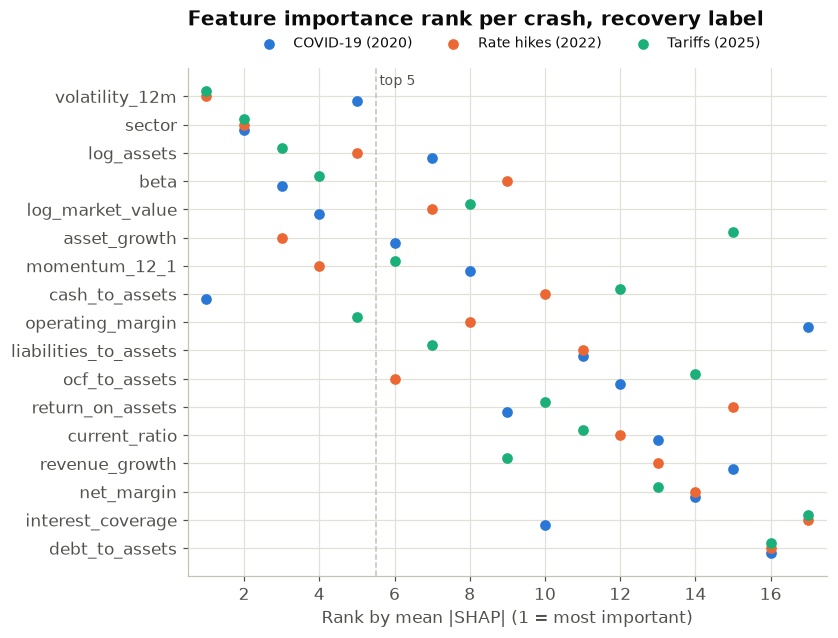

In [13]:
def feature_group(name):
    name = name.split("__", 1)[1]
    if name.startswith("sic_division") or name == "is_financial":
        return "sector"
    return name.replace("_missing", "")


def shap_importance(d, label):
    m = make_model("lgbm", FULL).fit(d, d[label])
    X = m.named_steps["prep"].transform(d)
    names = m.named_steps["prep"].get_feature_names_out()
    sv = shap.TreeExplainer(m.named_steps["model"]).shap_values(X)
    sv = sv[1] if isinstance(sv, list) else sv
    sv = pd.DataFrame(sv, columns=names)
    groups = [feature_group(n) for n in names]
    imp = sv.abs().T.groupby(groups).sum().T.mean()
    direction = {}
    for f in FEATURES:
        col = f"num__{f}"
        ok = d[f].notna().values
        rho = spearmanr(X[ok, list(names).index(col)], sv.loc[ok, col]).statistic if ok.sum() > 30 else np.nan
        direction[f] = np.sign(rho)
    return imp, pd.Series(direction)

importance, direction = {}, {}
for label in LABELS:
    for crash in ORDER:
        d = firms[firms["crash"] == crash].reset_index(drop=True)
        importance[(label, crash)], direction[(label, crash)] = shap_importance(d, label)

imp = pd.DataFrame(importance)
rank = imp.rank(ascending=False)
for label in LABELS:
    print(f"\n{LABELS[label]}: mean |SHAP| (rank)")
    t = imp[label].round(3).astype(str) + " (" + rank[label].astype(int).astype(str) + ")"
    print(t.loc[imp[label].mean(axis=1).sort_values(ascending=False).index, ORDER]
          .rename(columns=CRASH_SHORT).to_string())

# Figure: feature rank per crash, primary label
label = "recovered_12m"
order = imp[label].mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 6))
for k, crash in enumerate(ORDER):
    ax.scatter(rank.loc[order, (label, crash)], np.arange(len(order)) + (k - 1) * 0.18,
               color=CRASH_COLORS[crash], label=CRASH_LABELS[crash], s=36, zorder=3)
ax.axvline(5.5, color="#c3c2b7", linestyle="--", linewidth=1)
ax.text(5.6, len(order) - 0.6, "top 5", color="#52514e", fontsize=9)
ax.set_yticks(np.arange(len(order)), order)
ax.set_xlabel("Rank by mean |SHAP| (1 = most important)")
ax.set_xlim(0.5, len(order) + 0.5)
ax.grid(axis="x", color="#e1e0d9")
ax.set_title("Feature importance rank per crash, recovery label", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, fontsize=9)
save_figure(fig, "shap_ranks")
plt.show()

### Block 13: Spearman correlation of feature rankings

Between each pair of crashes.

In [14]:
rho_rows = []
for label in LABELS:
    for a, b in [("covid_2020", "rates_2022"), ("rates_2022", "tariff_2025"), ("covid_2020", "tariff_2025")]:
        r = spearmanr(imp[(label, a)], imp[(label, b)])
        rho_rows.append({"label": label, "pair": f"{CRASH_SHORT[a]} vs {CRASH_SHORT[b]}",
                         "spearman_rho": r.statistic, "p": r.pvalue})
rho = pd.DataFrame(rho_rows)
print(rho.set_index(["label", "pair"]).round(3).to_string())

                            spearman_rho      p
label         pair                             
recovered_12m 2020 vs 2022         0.537  0.026
              2022 vs 2025         0.615  0.009
              2020 vs 2025         0.375  0.138
beat_market   2020 vs 2022         0.520  0.033
              2022 vs 2025         0.265  0.305
              2020 vs 2025         0.338  0.184


### Block 14: Sort features into universal and crash-specific

Rule (decided 2026-11-08):
- **Universal:** in the top 5 by mean |SHAP| in all three crashes, with the same sign of effect.
- **Crash-specific:** in the top 5 in only one crash.
- **Shared by two:** in the top 5 in exactly two crashes, or in all three with a sign flip.
- **Minor:** never in the top 5.
- Sector is a group of one-hot columns with no single direction, so only its rank counts.

Stability: LightGBM is refit on 30 firm-level bootstrap resamples per crash, and each feature's share of resamples in the top 5 is shown.

In [15]:
TOP = 5
N_STAB = 30
rng = np.random.default_rng(SEED)
stability = {}
for label in LABELS:
    for crash in ORDER:
        d = firms[firms["crash"] == crash].reset_index(drop=True)
        hits = pd.Series(0.0, index=imp.index)
        for _ in range(N_STAB):
            sample = d.iloc[rng.integers(0, len(d), len(d))].reset_index(drop=True)
            m = make_model("lgbm", FULL).fit(sample, sample[label])
            X = m.named_steps["prep"].transform(d)
            names = m.named_steps["prep"].get_feature_names_out()
            sv = pd.DataFrame(np.abs(shap.TreeExplainer(m.named_steps["model"]).shap_values(X)), columns=names)
            g = sv.T.groupby([feature_group(n) for n in names]).sum().T.mean()
            hits[g.rank(ascending=False) <= TOP] += 1
        stability[(label, crash)] = hits / N_STAB
stability = pd.DataFrame(stability)


def sort_features(label):
    rows = []
    for f in imp.index:
        top = [c for c in ORDER if rank.loc[f, (label, c)] <= TOP]
        signs = {direction[(label, c)].get(f, np.nan) for c in ORDER}
        same_sign = len(signs) == 1 and not np.isnan(next(iter(signs)))
        if f == "sector":  # one-hot groups have no single direction
            group = "top 5 in all three (no direction)" if len(top) == 3 else (
                "minor" if not top else f"top 5 in {len(top)}")
        elif len(top) == 3 and same_sign:
            group = "universal"
        elif len(top) == 1:
            group = f"specific to {CRASH_SHORT[top[0]]}"
        elif len(top) >= 2:
            group = "shared by two" if len(top) == 2 else "all three, sign flips"
        else:
            group = "minor"
        rows.append({"feature": f, "group": group,
                     **{f"rank {CRASH_SHORT[c]}": int(rank.loc[f, (label, c)]) for c in ORDER},
                     **{f"top5 share {CRASH_SHORT[c]}": stability.loc[f, (label, c)] for c in ORDER},
                     "direction": "/".join("+" if direction[(label, c)].get(f, 0) > 0 else
                                           "-" if direction[(label, c)].get(f, 0) < 0 else "n/a" for c in ORDER)})
    out = pd.DataFrame(rows)
    out["mean rank"] = out[[f"rank {CRASH_SHORT[c]}" for c in ORDER]].mean(axis=1)
    return out.sort_values("mean rank").drop(columns="mean rank")

signals = {}
for label in LABELS:
    signals[label] = sort_features(label)
    print(f"\n{LABELS[label]}  (direction: sign of effect in 2020/2022/2025)")
    print(signals[label].round(2).to_string(index=False))


Recovered in 12 months  (direction: sign of effect in 2020/2022/2025)
              feature                             group  rank 2020  rank 2022  rank 2025  top5 share 2020  top5 share 2022  top5 share 2025   direction
               sector top 5 in all three (no direction)          2          2          2             0.60             1.00             0.97 n/a/n/a/n/a
       volatility_12m             all three, sign flips          5          1          1             0.80             1.00             1.00       +/-/-
           log_assets                     shared by two          7          5          3             0.20             0.37             1.00       +/+/+
                 beta                     shared by two          3          9          4             0.87             0.07             0.67       +/-/+
        momentum_12_1                  specific to 2022          8          4          6             0.20             0.70             0.17       +/-/+
     log_market_v

## Part 5b: Robustness of the main result

### Block 15: Without early acquisitions, and with a beta-adjusted label

Two checks on the within vs cross-crash gap (decided 2026-11-08):
1. **Early acquisitions.** Firms acquired before the 12-month mark keep the deal price as their outcome, so some are "not recovered" although survival analysis censors them. Drop them and refit.
2. **Beta-adjusted label.** Beating SPY rewards high-beta firms after a rebound. `beat_beta` asks whether the firm beat its own beta times SPY's return (beta capped at -1 and 4). If volatility still reverses across crashes under this label, the reversal isn't just market sensitivity.

LightGBM only, same settings and folds as Blocks 5 and 6.

In [16]:
def auc_grid(data, label):
    """LightGBM AUC for every train/test crash pair; train == test is within-crash CV."""
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    out = {}
    for tr in ORDER:
        d_tr = data[data["crash"] == tr].reset_index(drop=True)
        model = make_model("lgbm", FULL).fit(d_tr, d_tr[label])
        for te in ORDER:
            d_te = data[data["crash"] == te].reset_index(drop=True)
            if tr == te:
                p = np.zeros(len(d_te))
                for a, b in cv.split(d_te, d_te[label], groups=d_te["cik"]):
                    p[b] = make_model("lgbm", FULL).fit(d_te.iloc[a], d_te[label].iloc[a]).predict_proba(d_te.iloc[b])[:, 1]
            else:
                p = model.predict_proba(d_te)[:, 1]
            out[(CRASH_SHORT[tr], CRASH_SHORT[te])] = roc_auc_score(d_te[label], p)
    return pd.Series(out)

t12 = firms["crash"].map(lambda c: pd.Timestamp(CRASHES[c]["trough"]) + pd.DateOffset(months=12))
early_deal = (firms["exit_status"] == "acquired") & (firms["last_trade"] < t12)
print("Acquired before the 12-month mark:", early_deal.groupby(firms["crash"]).sum().rename(index=CRASH_SHORT).to_dict(),
      f"({firms.loc[early_deal, 'recovered_12m'].eq(0).sum()} labeled not recovered)")
firms["beat_beta"] = (firms["firm_return"] > firms["beta"].clip(-1, 4) * firms["spy_return"]).astype(int)
has_beta = firms["beta"].notna()
print("beat_beta rate:", firms[has_beta].groupby("crash")["beat_beta"].mean().rename(index=CRASH_SHORT).round(3).to_dict())

grid = pd.DataFrame({
    "recovered: all": auc_grid(firms, "recovered_12m"),
    "recovered: no early deals": auc_grid(firms[~early_deal], "recovered_12m"),
    "beat SPY": auc_grid(firms, "beat_market"),
    "beat beta x SPY": auc_grid(firms[has_beta], "beat_beta"),
})
grid.index.names = ["train", "test"]
print("\nLightGBM AUC:")
print(grid.round(3).to_string())
within_rows = [i for i in grid.index if i[0] == i[1]]
cross_rows = [i for i in grid.index if i[0] != i[1]]
print("\nMean within vs cross:")
print(pd.DataFrame({"within": grid.loc[within_rows].mean(), "cross": grid.loc[cross_rows].mean()}).round(3).to_string())

# Does volatility's direction still flip under the beta-adjusted label?
flip = {CRASH_SHORT[c]: round(spearmanr(g["volatility_12m"], g["beat_beta"], nan_policy="omit").statistic, 3)
        for c, g in firms[has_beta].groupby("crash")}
print("\nSpearman of volatility with beat_beta, by crash:", flip)

Acquired before the 12-month mark: {'2020': 83, '2022': 159, '2025': 135} (199 labeled not recovered)
beat_beta rate: {'2020': 0.474, '2022': 0.319, '2025': 0.406}



LightGBM AUC:
            recovered: all  recovered: no early deals  beat SPY  beat beta x SPY
train test                                                                      
2020  2020           0.678                      0.680     0.714            0.677
      2022           0.457                      0.453     0.443            0.467
      2025           0.517                      0.510     0.449            0.409
2022  2020           0.456                      0.455     0.488            0.502
      2022           0.703                      0.714     0.731            0.736
      2025           0.602                      0.603     0.534            0.549
2025  2020           0.456                      0.447     0.446            0.393
      2022           0.579                      0.591     0.542            0.560
      2025           0.674                      0.676     0.678            0.694

Mean within vs cross:
                           within  cross
recovered: all              0.

## Part 6: Notes for the report

Numbers are from the 2026-11-09 rerun, after the audit fixes (Task 5b).

**Within a crash, fundamentals help** (Blocks 4, 5, 9 to 11)
- LightGBM and random forest reach AUC 0.67 to 0.73, vs 0.62 to 0.67 for the sector-and-size baseline. LightGBM's gain is +0.02 to +0.07, and every firm-grouped bootstrap interval is above zero.
- After the Holm correction, 16 of 18 within-crash model-vs-baseline tests are significant. The exceptions are logistic regression on 2020 recovery and LightGBM on 2025 recovery. Overall, 47 of 72 tests are significant.

**Across crashes, they don't transfer** (Blocks 6 to 8, main result)
- Cross-crash AUC falls to 0.42 to 0.60. Pairs that involve 2020 are at or near chance (0.42 to 0.52), so what predicted recovery in 2020 doesn't carry over.
- 2022 and 2025 transfer partly to each other (0.53 to 0.60 for LightGBM), including the forward pair.
- The full models lose more than the baseline. Mean AUC lost is 0.18 vs 0.13 for recovery, and 0.23 vs 0.14 for beating SPY. Trained on the other two crashes, LightGBM is worse than the baseline: pooled gain -0.055 for recovery (95% CI -0.066 to -0.044) and -0.048 for beating SPY (-0.058 to -0.038). The extra fundamentals fit crash-specific patterns.
- This isn't a change in feature levels. Within-crash percentile features change cross-crash AUC by only -0.004 on average.
- It isn't driven by firm overlap either. Firms also in the training crash score no better than new firms.

**Universal vs crash-specific signals** (Blocks 12 to 14)
- No feature is universal by the rule (top 5 in all three crashes with the same sign). Sector is in the top 5 everywhere but has no single direction. Firm size (`log_assets`, bigger is better) comes closest for recovery: same sign in all three, top 5 in 2022 and 2025, rank 7 in 2020.
- Pre-crash volatility explains the reversal. It's the top signal in 2022 and 2025, where calmer firms did better, but in 2020 more volatile firms did better. Beta flips in the same way.
- Crash-specific signals for recovery: cash to assets and market value in 2020 (cash mattered in a sudden shutdown), asset growth and momentum in 2022, operating margin in 2025.
- Importance rankings for recovery agree for 2022 vs 2025 (Spearman 0.62, p = 0.009) and partly for 2020 vs 2022 (0.54, p = 0.03). They don't agree for 2020 vs 2025 (0.38, p = 0.14).

**Robustness** (Block 15)
- Dropping the 377 rows acquired before the 12-month mark (199 labeled not recovered) changes nothing: mean within-crash AUC 0.690 vs 0.685, cross-crash 0.510 vs 0.511.
- With a beta-adjusted label (beat beta times SPY's return), the gap is the same (within 0.702, cross 0.480), and volatility still flips sign (Spearman +0.22 in 2020, -0.19 in 2022, -0.17 in 2025). So the reversal isn't just market sensitivity.

**Caveats**
- Brier scores are inflated by balanced class weights, which shift probabilities toward 0.5. Compare models on AUC and PR-AUC.
- Within a crash each firm appears once, so firm grouping matters most for pooled results (Block 10's pooled row).